# TF-IDF Analysis for Transcript Words

Analyzes vocabulary patterns across transcripts using TF-IDF (Term Frequency-Inverse Document Frequency). This helps identify:
- Words that are distinctive to specific recordings
- Common vs. rare words in the dataset
- Word importance for classification tasks (Dementia, MCI, HC)

In [42]:
import re
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.stem import WordNetLemmatizer

from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    precision_recall_fscore_support
)
from sklearn.utils.sparsefuncs import mean_variance_axis
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

nltk.download('wordnet', quiet=True)

import optuna
import cognospeak.dataloader as dataloader

## Data Loading and Preprocessing

In [43]:
loader = dataloader.TranscriptLoader()
transcript_paths = loader.discover_transcript_files()

frames_dict = loader.load_all_transcripts(transcript_paths)
metadata = loader.load_metadata()

lemmatizer = WordNetLemmatizer()

def lemma_tokenizer(text):
    tokens = re.split(r'\W+', text.lower())
    return [lemmatizer.lemmatize(w) for w in tokens if len(w) > 1]

diagnosis_by_recording = {
    row['recording']: row['diagnosis']
    for _, row in metadata[['recording', 'diagnosis']].dropna().iterrows()
}

TARGET_TASKS = ('SFT', 'PFT')
# TARGET_DIAGNOSES = ('DEMENTIA', 'MCI', 'HC')
# TARGET_DIAGNOSES = ('DEMENTIA', 'HC')
# TARGET_DIAGNOSES = ('DEMENTIA', 'MCI')
# TARGET_DIAGNOSES = ('MCI', 'HC')
TARGET_DIAGNOSES = ('NON-HEALTHY', 'HC')

task_diagnosis_frames = {
    task: {diagnosis: {} for diagnosis in TARGET_DIAGNOSES}
    for task in TARGET_TASKS
}

# for stem, df in frames_dict.items():
#     if len(df) == 0: continue

#     if 'task' in df.columns:
#         task = str(df['task'].iloc[0]).upper()
#     else:
#         task = 'SFT' if 'SFT' in stem.upper() else 'PFT' if 'PFT' in stem.upper() else 'UNKNOWN'

#     recording = str(df['recording'].iloc[0]) if 'recording' in df.columns else None
#     diagnosis = diagnosis_by_recording.get(recording, 'UNKNOWN')

#     if task in TARGET_TASKS and diagnosis in TARGET_DIAGNOSES:
#         task_diagnosis_frames[task][diagnosis][stem] = df


"""
Conducts two-way classification on HC and Non-healthy group
"""
for stem, df in frames_dict.items():
    if len(df) == 0: continue

    if 'task' in df.columns:
        task = str(df['task'].iloc[0]).upper()
    else:
        task = 'SFT' if 'SFT' in stem.upper() else 'PFT' if 'PFT' in stem.upper() else 'UNKNOWN'

    recording = str(df['recording'].iloc[0]) if 'recording' in df.columns else None
    raw_diagnosis = diagnosis_by_recording.get(recording, 'UNKNOWN')

    # GROUPING LOGIC:
    # If the patient is MCI or DEMENTIA, map them to 'NON-HEALTHY'
    if raw_diagnosis in ['DEMENTIA', 'MCI']:
        diagnosis = 'NON-HEALTHY'
    else:
        diagnosis = raw_diagnosis  # Usually 'HC'

    if task in TARGET_TASKS and diagnosis in TARGET_DIAGNOSES:
        task_diagnosis_frames[task][diagnosis][stem] = df

def build_corpus(dataframes, min_tokens=2):
    corpus = []
    for df in dataframes:
        tokens = [t.strip() for t in df['token'].astype(str).tolist() if t.strip()]
        if len(tokens) < min_tokens: continue
        text = ' '.join(df['token'].astype(str).tolist())
        corpus.append(text)
    return corpus

## Utility Functions for TF-IDF and Visualization

In [44]:

def plot_tfidf_comparison(task_name, task_data, n_limit=20):
    fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=False)
    fig.suptitle(f"Top {n_limit} Stemmed Terms: {task_name}", fontsize=18, fontweight='bold')
    
    colors = {
        'DEMENTIA': '#e31a1c', # Bright Red
        'MCI': "#000dff", # Bright Blue
        'HC': '#33a02c', # Bright Green
        'NON-HEALTHY': '#e31a1c' # Bright Red
    }

    for idx, diagnosis in enumerate(['HC', 'MCI', 'DEMENTIA']):
    # for idx, diagnosis in enumerate(['HC', 'NON-HEALTHY']):
        ax = axes[idx]
        diagnosis_frames = task_data.get(diagnosis, {})
        corpus = build_corpus(diagnosis_frames.values())

        if not corpus:
            ax.text(0.5, 0.5, "No Data Available", ha='center', va='center')
            ax.set_title(f"{diagnosis}")
            continue

        vectorizer = TfidfVectorizer(tokenizer=lemma_tokenizer, token_pattern=None)
        X = vectorizer.fit_transform(corpus)
        feature_names = vectorizer.get_feature_names_out()
        mean_scores = mean_variance_axis(X, axis=0)[0]
        
        sorted_indices = mean_scores.argsort()[::-1][:n_limit]
        top_terms = [feature_names[i] for i in sorted_indices]
        top_values = [mean_scores[i] for i in sorted_indices]

        ax.barh(top_terms, top_values, color=colors.get(diagnosis, 'skyblue'))
        ax.set_title(f"{diagnosis} (n={len(corpus)})", fontsize=14)
        ax.invert_yaxis()
        ax.set_xlabel("Mean TF-IDF Score")
        ax.grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

## Machine Learning Pipeline

In [45]:

def objective(trial, X, y):
    param_grid = {
        'tfidf__max_features': trial.suggest_int('tfidf__max_features', 20, 100),
        'tfidf__max_df': trial.suggest_float('tfidf__max_df', 0.75, 0.8),
        'tfidf__min_df': trial.suggest_int('tfidf__min_df', 2, 5),
        'tfidf__binary': trial.suggest_categorical('tfidf__binary', [True, False]),
        'tfidf__sublinear_tf': trial.suggest_categorical('tfidf__sublinear_tf', [True, False]),
        'clf__C': trial.suggest_float('clf__C', 0.1, 10.0, log=True),
        'clf__class_weight': trial.suggest_categorical('clf__class_weight', ['balanced', None])
    }
    
    pipeline = build_pipeline()
    
    pipeline.set_params(**param_grid)
    
    score = cross_val_score(pipeline, X, y, cv=5, scoring='f1_macro').mean()
    return score

# fusion_preprocessor = ColumnTransformer([
#     ('tfidf', TfidfVectorizer(
#         tokenizer=lemma_tokenizer,
#         token_pattern=None,
#         max_features=50,
#         binary=False,
#         sublinear_tf=False,
#         max_df=0.75,
#         min_df=5
#     )),
#     ('meta', StandardScaler(), ['age'])
# ])

def build_pipeline():
    return Pipeline([
    ('tfidf', TfidfVectorizer(
        tokenizer=lemma_tokenizer,
        token_pattern=None,
        max_features=50,
        binary=False,
        sublinear_tf=False,
        max_df=0.75,
        min_df=5
    )),
    ('clf', LogisticRegression(
        class_weight='balanced', 
        # solver='lbfgs',
        # C=0.1,
        random_state=42,
        max_iter=1000
    ))
    # ('clf', RandomForestClassifier(
    #     class_weight='balanced', # Crucial for your MCI/Dementia minority classes
    #     random_state=42
    # ))
])

def run_pipeline_tuning(X, y, n_trials=30):
    study = optuna.create_study(direction='maximize')

    study.optimize(lambda trial: objective(trial, X, y), n_trials=n_trials)
    
    print("\n--- Optuna Optimization Results ---")
    print(f"Best F1-Score: {study.best_value:.4f}")
    print(f"Best Parameters: {study.best_params}")
    
    return study.best_params


def build_dataset(task_diagnosis_frames, tasks, diagnoses, min_tokens=2):
    X, y = [], []
    skipped = 0 
    for task in tasks:
        for diagnosis in diagnoses:
            frames = task_diagnosis_frames[task][diagnosis]
            for stem, df in frames.items():
                tokens = [t.strip() for t in df['token'].astype(str).tolist() if t.strip()]
                if len(tokens) < min_tokens:
                    skipped += 1
                    continue
                X.append(' '.join(tokens))
                y.append(diagnosis)
    print(f"Skipped {skipped} short transcripts")
    return X, y

def run_cv_experiment(X, y, k=5, pipeline=build_pipeline()):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    metrics = []
    conf_matrices = []

    all_y_true = []
    all_y_pred = []
    for train_idx, test_idx in skf.split(X, y):
        X_train, X_test = [X[i] for i in train_idx], [X[i] for i in test_idx]
        y_train, y_test = [y[i] for i in train_idx], [y[i] for i in test_idx]

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        acc = accuracy_score(y_test, y_pred)
        prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
        cm = confusion_matrix(y_test, y_pred, labels=TARGET_DIAGNOSES)

        metrics.append((acc, prec, rec, f1))
        conf_matrices.append(cm)

    return np.array(metrics), conf_matrices, all_y_pred, all_y_true

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

def plot_avg_confusion_matrix(conf_matrices, labels, all_y_true, all_y_pred, task_name):
    # 1. Sum the matrices to get the total counts across all 90-100 participants
    total_cm = np.sum(conf_matrices, axis=0)
    total_samples = total_cm.sum()
    
    # 2. Calculate percentages based on the total population
    cm_percent_total = (total_cm.astype('float') / total_samples) * 100

    # 3. Create the annotation labels (Count \n Percentage)
    annot_labels = []
    for i in range(len(labels)):
        row = []
        for j in range(len(labels)):
            count = int(total_cm[i, j])
            percent = cm_percent_total[i, j]
            row.append(f'{count}\n({percent:.1f}%)')
        annot_labels.append(row)

    # 4. Create the plot
    fig, ax = plt.subplots(figsize=(8, 6))
    
    sns.heatmap(total_cm, 
                annot=annot_labels, 
                fmt='', 
                cmap='Blues',
                xticklabels=labels,
                yticklabels=labels,
                cbar_kws={'label': 'Count'},
                ax=ax)

    # Styling labels and title
    ax.set_xlabel('Predicted Diagnosis', fontsize=12, fontweight='bold')
    ax.set_ylabel('True Diagnosis', fontsize=12, fontweight='bold')
    ax.set_title(f'TF-IDF Confusion Matrix: {task_name}',
                 fontsize=14, fontweight='bold', pad=20)

    # 5. Calculate and add the F1 Score box
    # Using macro because we have 3 classes (or binary macro)
    f1 = f1_score(all_y_true, all_y_pred, average='macro')
    
    ax.text(0.5, -0.2, f'Macro F1 Score: {f1:.4f}',
            transform=ax.transAxes, ha='center', fontsize=11,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()
    plt.show()

## Detailed Analysis

In [46]:
from sklearn.metrics import classification_report

def summarise_detailed_results(metrics, all_y_true, all_y_pred):
    mean = metrics.mean(axis=0)
    std = metrics.std(axis=0)

    print("\n" + "="*30)
    print("DETAILED PERFORMANCE METRICS")
    print("="*30)
    print(f"Overall Accuracy: {mean[0]:.3f} ± {std[0]:.3f}")
    print(f"Weighted F1:      {mean[3]:.3f} ± {std[3]:.3f}")
    print("-" * 30)
    
    # This shows Recall and Precision per class
    print("Per-Class Breakdown (Aggregated):")
    print(classification_report(all_y_true, all_y_pred, target_names=TARGET_DIAGNOSES))

## SFT Experiment

In [47]:
task = 'SFT'

print(f"\n===== TASK: {TARGET_TASKS[0]} =====")
X, y = build_dataset(task_diagnosis_frames, [task], TARGET_DIAGNOSES)

metrics, cms, all_y_pred, all_y_true = run_cv_experiment(X, y)
summarise_detailed_results(metrics, all_y_true, all_y_pred)

mean, std = metrics.mean(axis=0), metrics.std(axis=0)
print(f"Accuracy: {mean[0]:.3f} ± {std[0]:.3f}")
print(f"F1-score: {mean[3]:.3f} ± {std[3]:.3f}")


===== TASK: SFT =====
Skipped 0 short transcripts

DETAILED PERFORMANCE METRICS
Overall Accuracy: 0.638 ± 0.106
Weighted F1:      0.625 ± 0.107
------------------------------
Per-Class Breakdown (Aggregated):
              precision    recall  f1-score   support

 NON-HEALTHY       0.59      0.60      0.59        40
          HC       0.68      0.67      0.67        51

    accuracy                           0.64        91
   macro avg       0.63      0.63      0.63        91
weighted avg       0.64      0.64      0.64        91

Accuracy: 0.638 ± 0.106
F1-score: 0.625 ± 0.107


## SFT Confusion Matrix

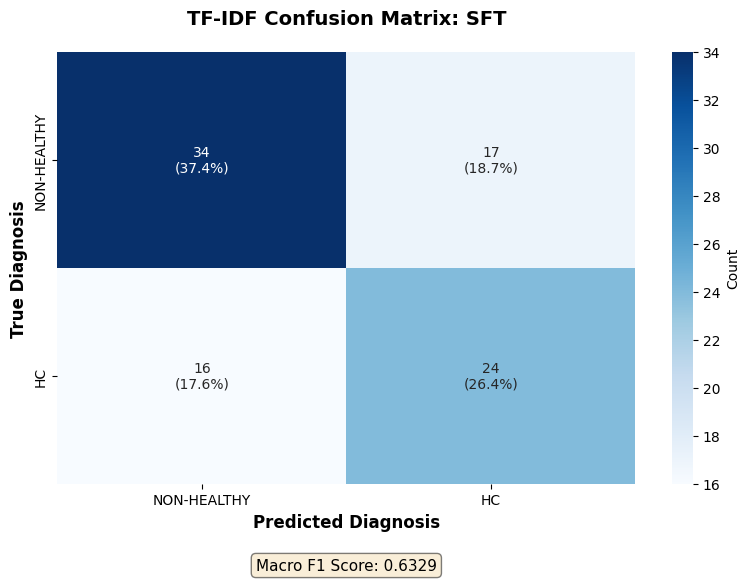

In [48]:
plot_avg_confusion_matrix(cms, TARGET_DIAGNOSES, all_y_true, all_y_pred, task)

## SFT TF-IDF Ranking

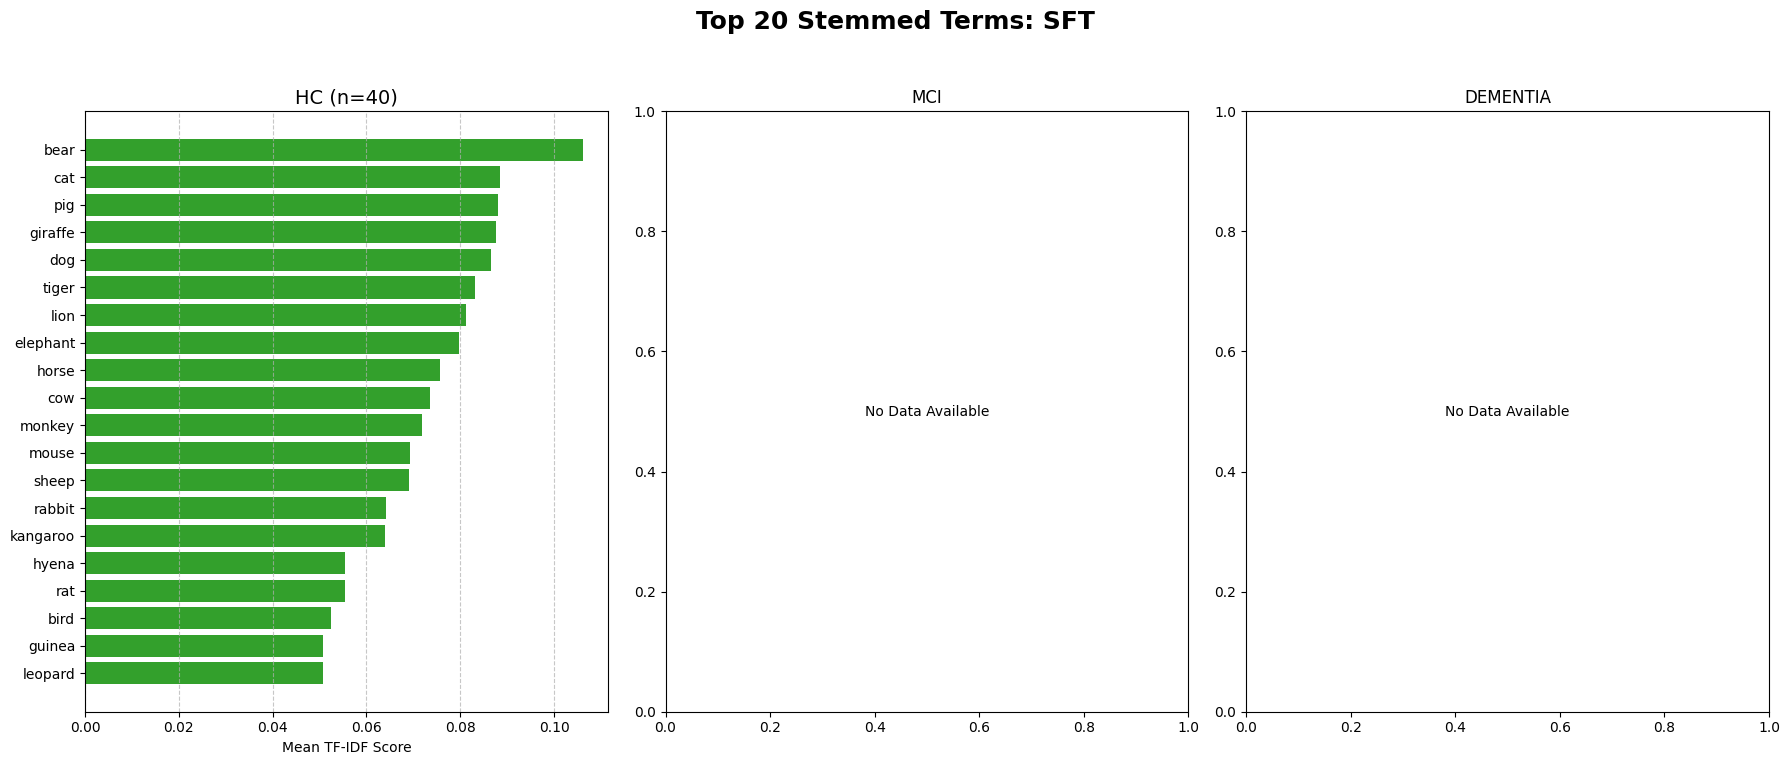

In [49]:
plot_tfidf_comparison(task, task_diagnosis_frames[task], 20)

## PFT Experiment

In [50]:
task = 'PFT'

print(f"\n===== TASK: {TARGET_TASKS[1]} =====")
X, y = build_dataset(task_diagnosis_frames, [task], TARGET_DIAGNOSES)

metrics, cms, all_y_pred, all_y_true = run_cv_experiment(X, y)
summarise_detailed_results(metrics, all_y_true, all_y_pred)

mean, std = metrics.mean(axis=0), metrics.std(axis=0)
print(f"Accuracy: {mean[0]:.3f} ± {std[0]:.3f}")
print(f"F1-score: {mean[3]:.3f} ± {std[3]:.3f}")




===== TASK: PFT =====
Skipped 1 short transcripts

DETAILED PERFORMANCE METRICS
Overall Accuracy: 0.529 ± 0.110
Weighted F1:      0.501 ± 0.101
------------------------------
Per-Class Breakdown (Aggregated):
              precision    recall  f1-score   support

 NON-HEALTHY       0.47      0.40      0.43        40
          HC       0.56      0.63      0.60        49

    accuracy                           0.53        89
   macro avg       0.52      0.52      0.51        89
weighted avg       0.52      0.53      0.52        89

Accuracy: 0.529 ± 0.110
F1-score: 0.501 ± 0.101


## PFT Confusion Matrix

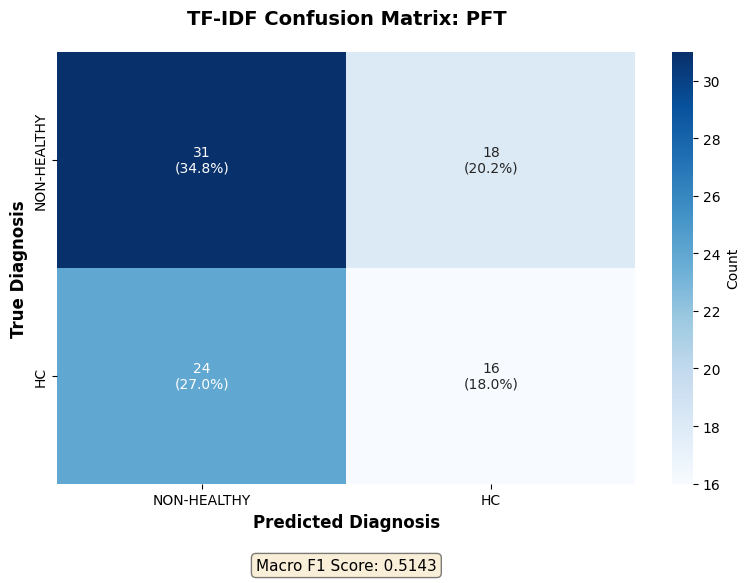

In [51]:
plot_avg_confusion_matrix(cms, TARGET_DIAGNOSES, all_y_true, all_y_pred, task)

## PFT TF-IDF Ranking

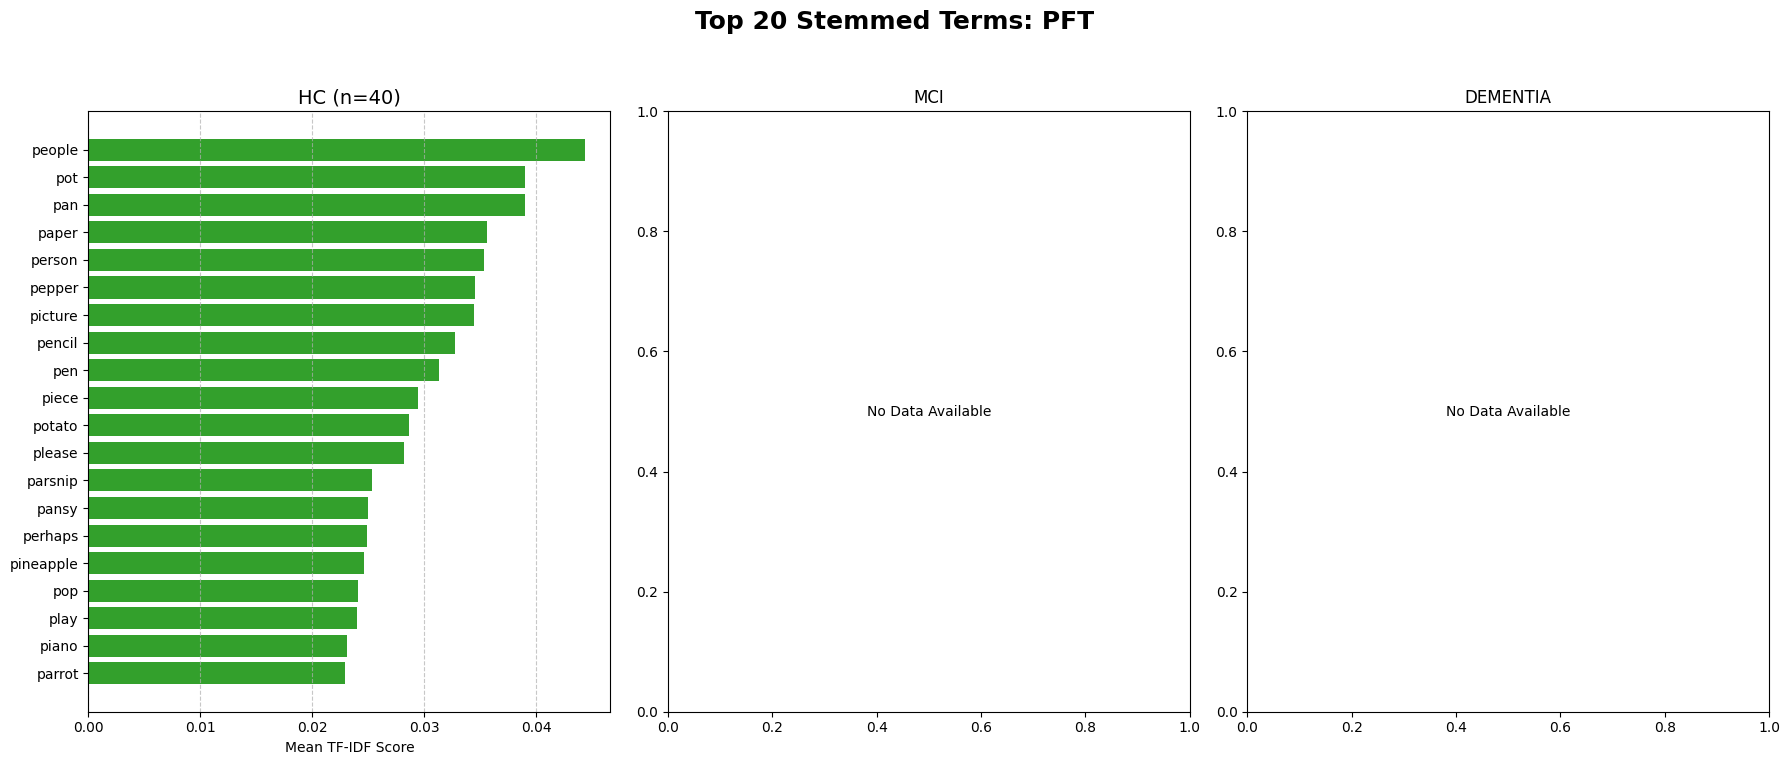

In [52]:
plot_tfidf_comparison(task, task_diagnosis_frames[task], 20)